# N108: frozen offline and adapting transition controllers

Status: **complete**. Active arm: **preparation/checks**.

Three independent runs use the same91,968 reserved images in order. Every image
learner restores the ORIGINAL pre-96k parent; offline-trained or other-arm image
weights/momentum never transfer. The42 offline clips/4,032 images stay excluded.

| Arm | Transition predictor | Planning horizon |
| --- | --- | ---: |
| Frozen offline · H1 | Offline weights stay fixed; chooses rates | 1 |
| Adaptive · H1 | Starts at exactly the offline fit, then learns actual feedback | 1 |
| Adaptive · H2 | Same initialization/adaptation; plans2 actions and applies first | 2 |

New nominal LR = **1/4 of N107 nominal LR**. Actions are {skip,1/4 new nominal,1 new nominal}, hence {0,1/16,1/4} of N107 nominal. The same offline fit is evaluated at the actual physical rate: its rate argument and both action-history inputs are scaled by1/4. The smallest rate uses the fitted response curve between skip and the old quarter-rate; no new offline labels are collected.

Actions: {skip,1/4 nominal,1 nominal}. All use the same5% nonzero exploration,
paired action/view seeds, numerical rollback and64-arrival cooldown. Both adaptive
models warm-start with the actual offline TRAINING sufficient statistics and
coefficients. Each successful chosen positive update supplies one measured
RankMe/reconstruction/variance change vector. Discount past evidence with a256
successful-update half-life. Scalers/target scales, ridge penalties, objective
and all other settings stay fixed. Skip/failed/untried/imagined actions do not
train a model. The frozen predictor never adapts, although its image-model plant
does train at the rates it selects.

H1 minimizes next predicted original J. H2 minimizes summed J over two predicted
states, applies only the first action and replans after real feedback. Future raw
image statistics are held at current values; no future images, measured health,
task scores or controller updates are fed into imagined states. The original
fixed-reference J uses .25 rank and .25 variance deficit penalties.

An immutable offline shadow also forecasts each adaptive arm's ACTUAL states and
chosen actions. Paired shadow errors isolate prediction adaptation from different
plant trajectories. All forecasts are logged before feedback. One-step errors
below exclude trivial identity skips; only chosen actions have measured outcomes.
Two-step error selects the already-logged forecast for the subsequently executed
action pair, without giving future actions to the earlier controller. Include
nontrivial windows and clip boundaries; exclude numerical failures.

Task labels appear only in fixed evaluation readouts, never in predictor inputs,
updates or action decisions. This is prequential adaptation, not offline refitting
on this stream. The source96k history was inspected in older project experiments.
All arms compute two-step forecasts for common diagnostics; only H2 controls with
them, so inference timings include that diagnostic work.

| Arm | Saved images | Plant updates | Predictor updates | Available late accuracy (%) | Recorded time (min) |
| --- | ---: | ---: | ---: | ---: | ---: |
| Frozen offline · H1 | 91,968 | 14,329 | 0 | 62.026 | 33.41 |
| Adaptive · H1 | 91,968 | 17,324 | 17,324 | 60.242 | 38.71 |
| Adaptive · H2 | 91,968 | 18,059 | 18,059 | 59.844 | 40.26 |

Common coverage across all three arms: **91,968**. Available table means use each arm's saved coverage; primary comparisons use common scheduled30k--91,968 checkpoints.

## Positive-update one-step forecast RMSE

| Arm | Output | Active model | Frozen shadow, same states/actions | Persistence | Positive updates |
| --- | --- | ---: | ---: | ---: | ---: |
| Frozen offline · H1 | RankMe | 0.00779207 | 0.00779207 | 0.00846194 | 14,329 |
| Frozen offline · H1 | Reconstruction loss | 0.000956775 | 0.000956775 | 0.000918773 | 14,329 |
| Frozen offline · H1 | Variance | 2.92235e-05 | 2.92235e-05 | 3.35466e-05 | 14,329 |
| Adaptive · H1 | RankMe | 0.00530933 | 0.00544686 | 0.00611265 | 17,324 |
| Adaptive · H1 | Reconstruction loss | 0.000567199 | 0.000677183 | 0.000641024 | 17,324 |
| Adaptive · H1 | Variance | 1.91631e-05 | 1.8677e-05 | 2.1737e-05 | 17,324 |
| Adaptive · H2 | RankMe | 0.00560306 | 0.00559853 | 0.00628638 | 18,059 |
| Adaptive · H2 | Reconstruction loss | 0.000559377 | 0.000681897 | 0.000633805 | 18,059 |
| Adaptive · H2 | Variance | 1.75519e-05 | 1.69606e-05 | 1.97132e-05 | 18,059 |

RMSE is in native metric units. Different policies visit different states; the frozen-shadow comparison is paired within each plant trajectory. Per-action and two-step numbers/counts are saved in comparison.json.


## Balanced audit linear accuracy (%)

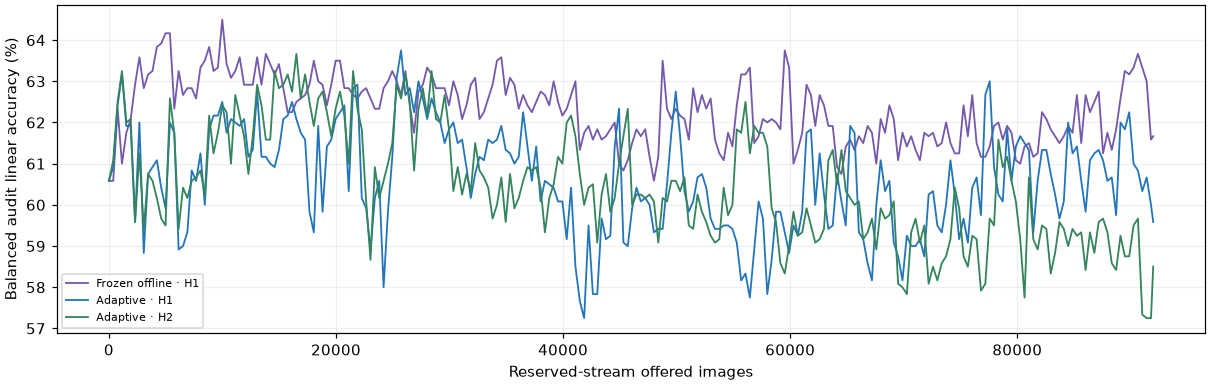



## RankMe

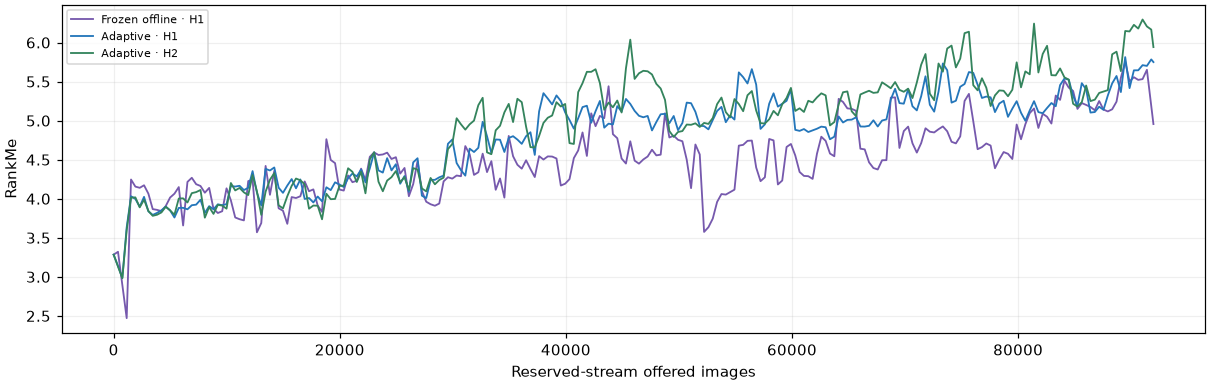



## Fixed-bank reconstruction loss

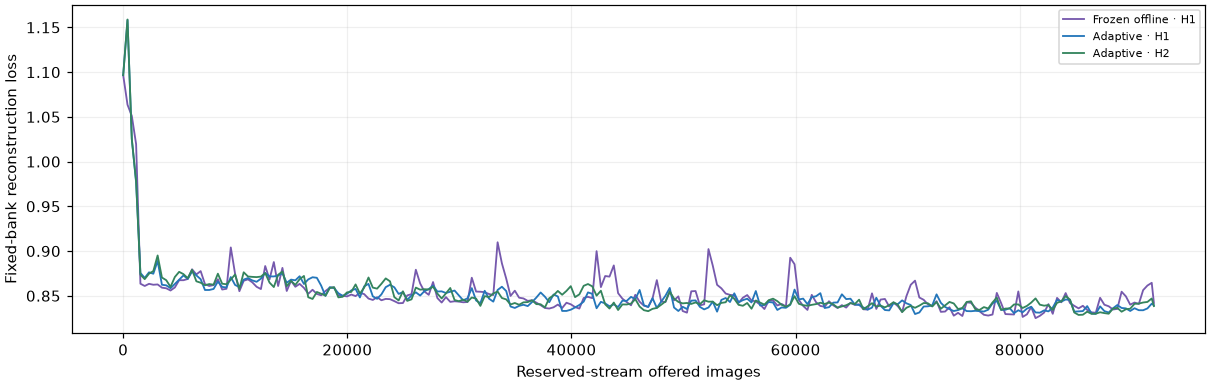



## Variance

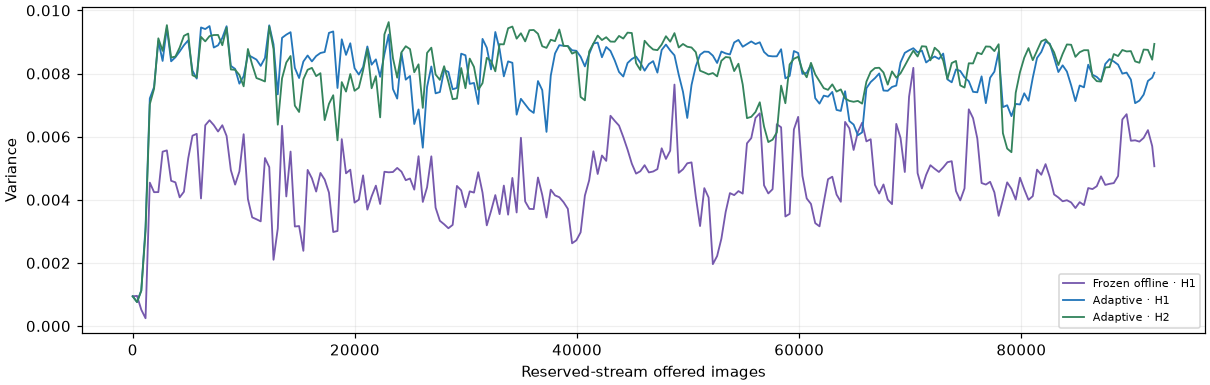



## Original fixed-bank J

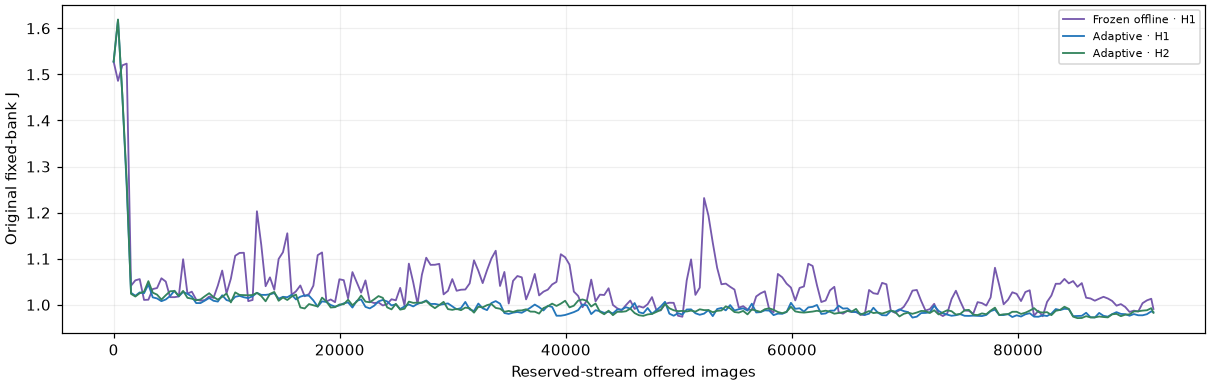



## Covariance

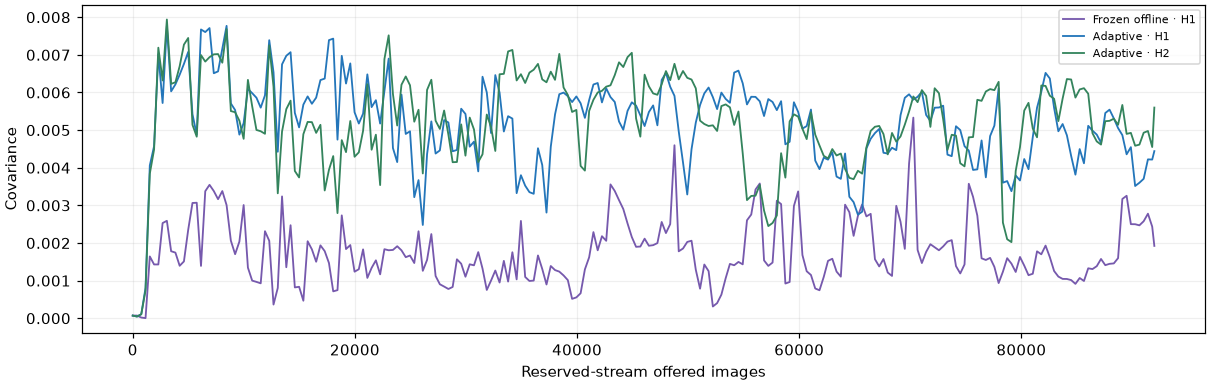



## Actual plant outputs and one-step forecasts

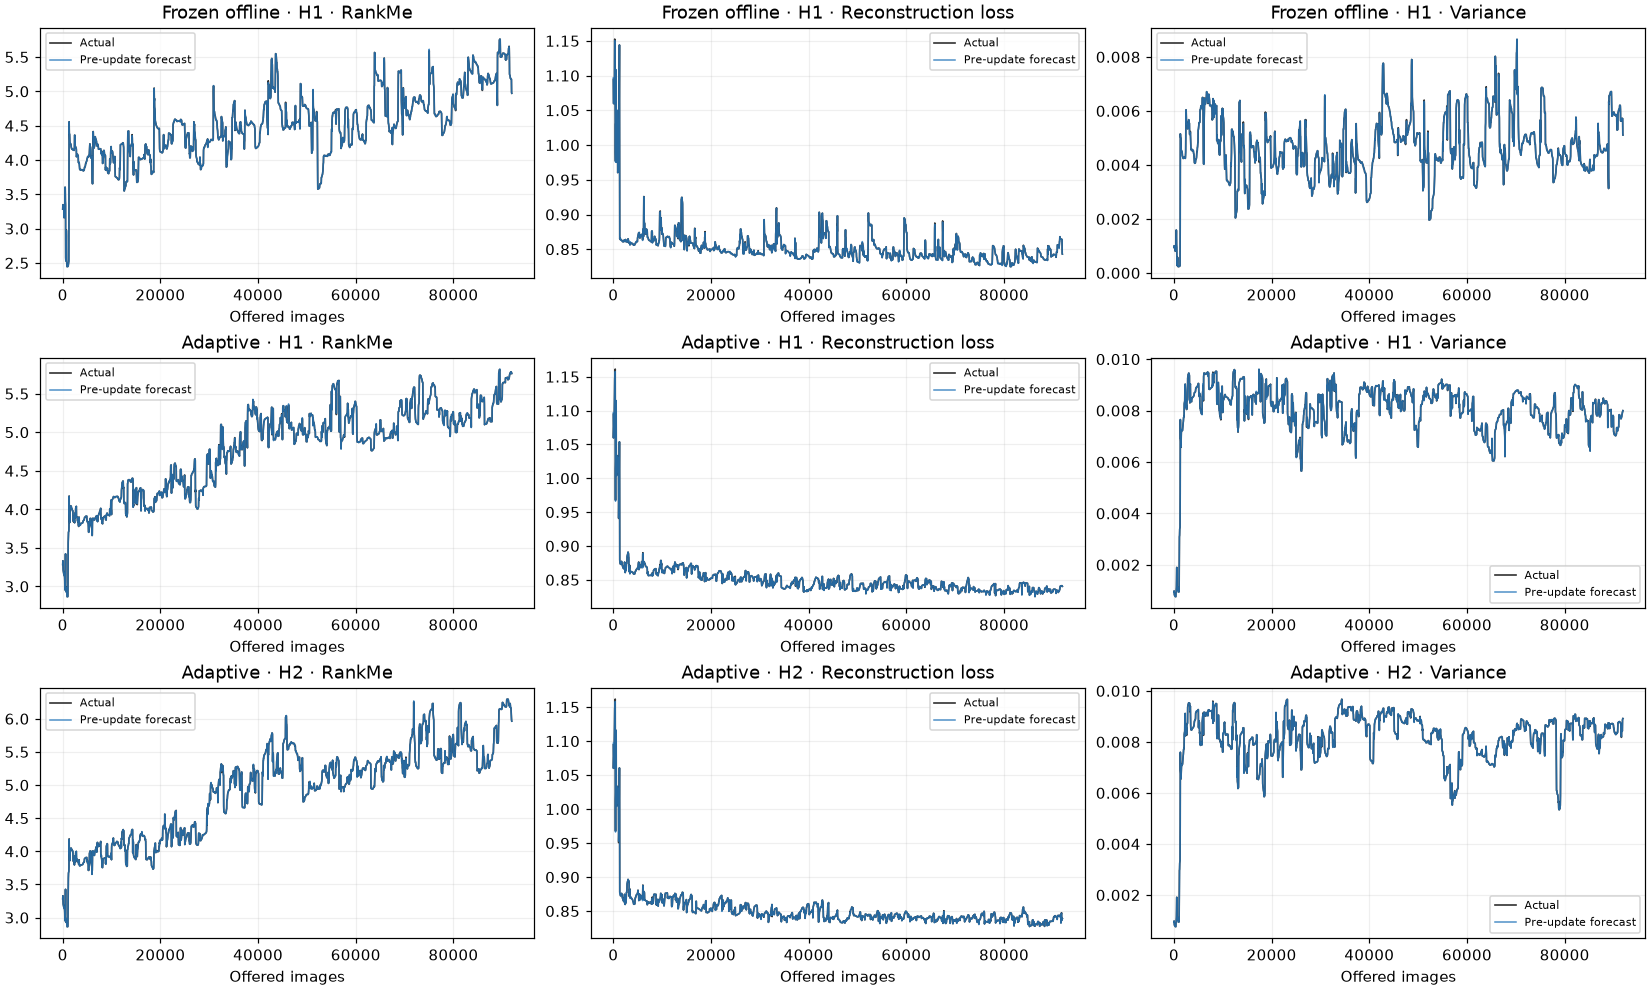

Display subsamples every32 arrivals; RMSE uses all successful positive updates and excludes identity skips.

## One-step positive-update RMSE

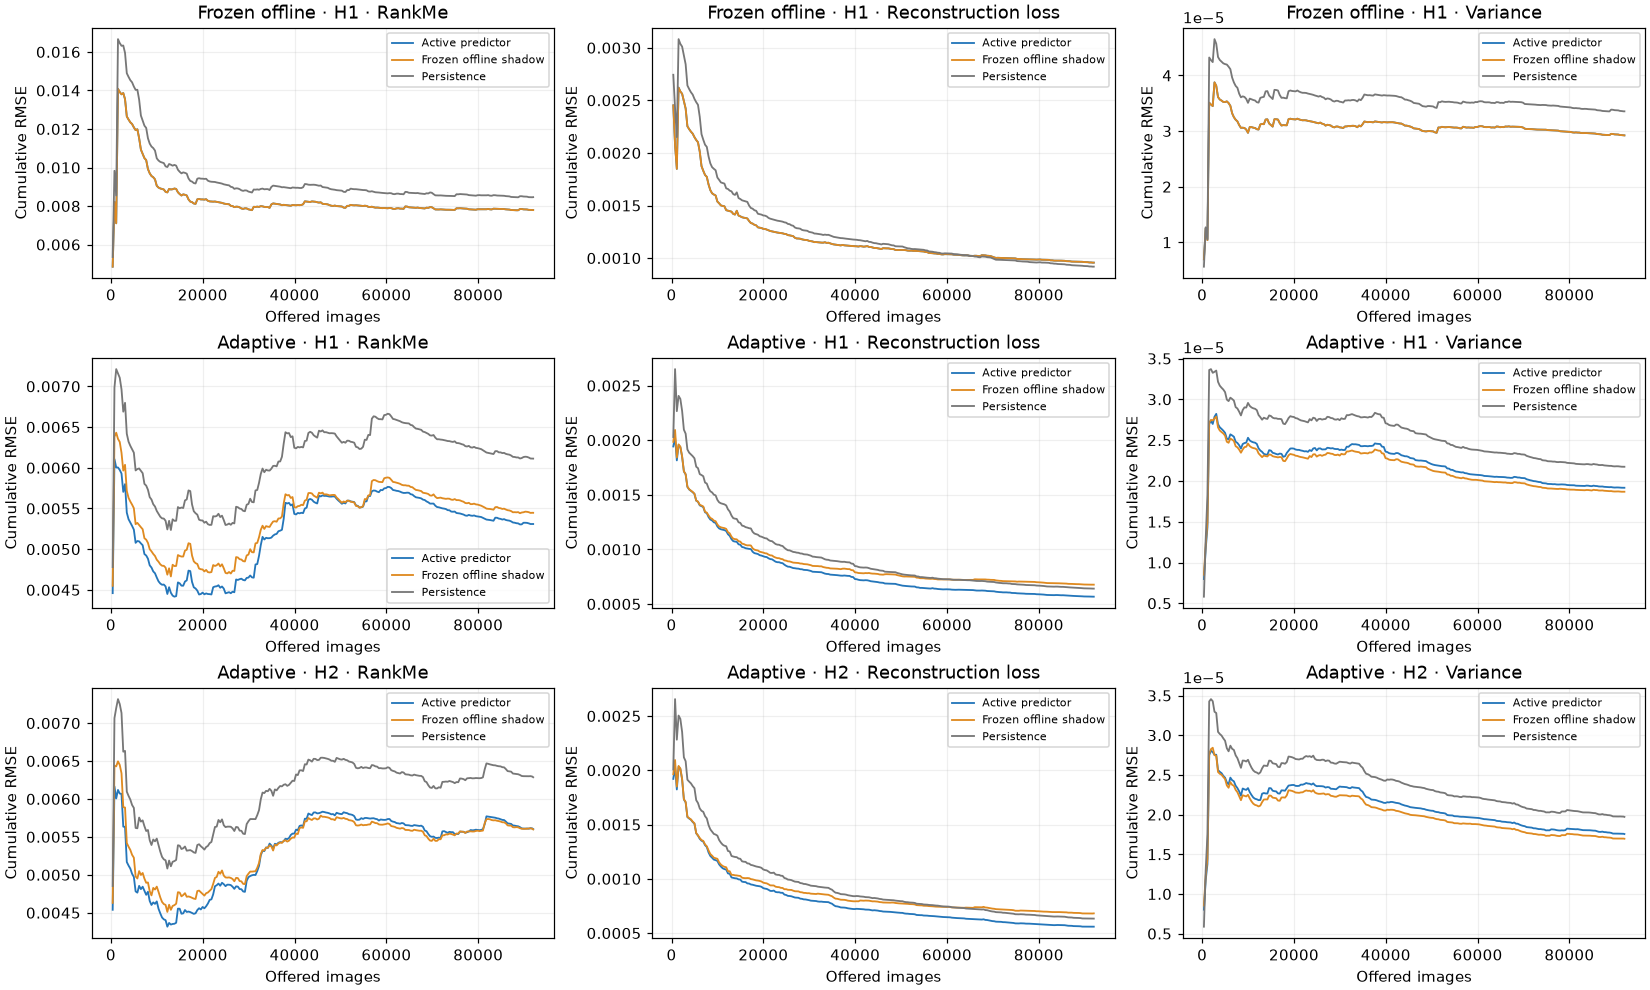



## Two-step nontrivial-window RMSE

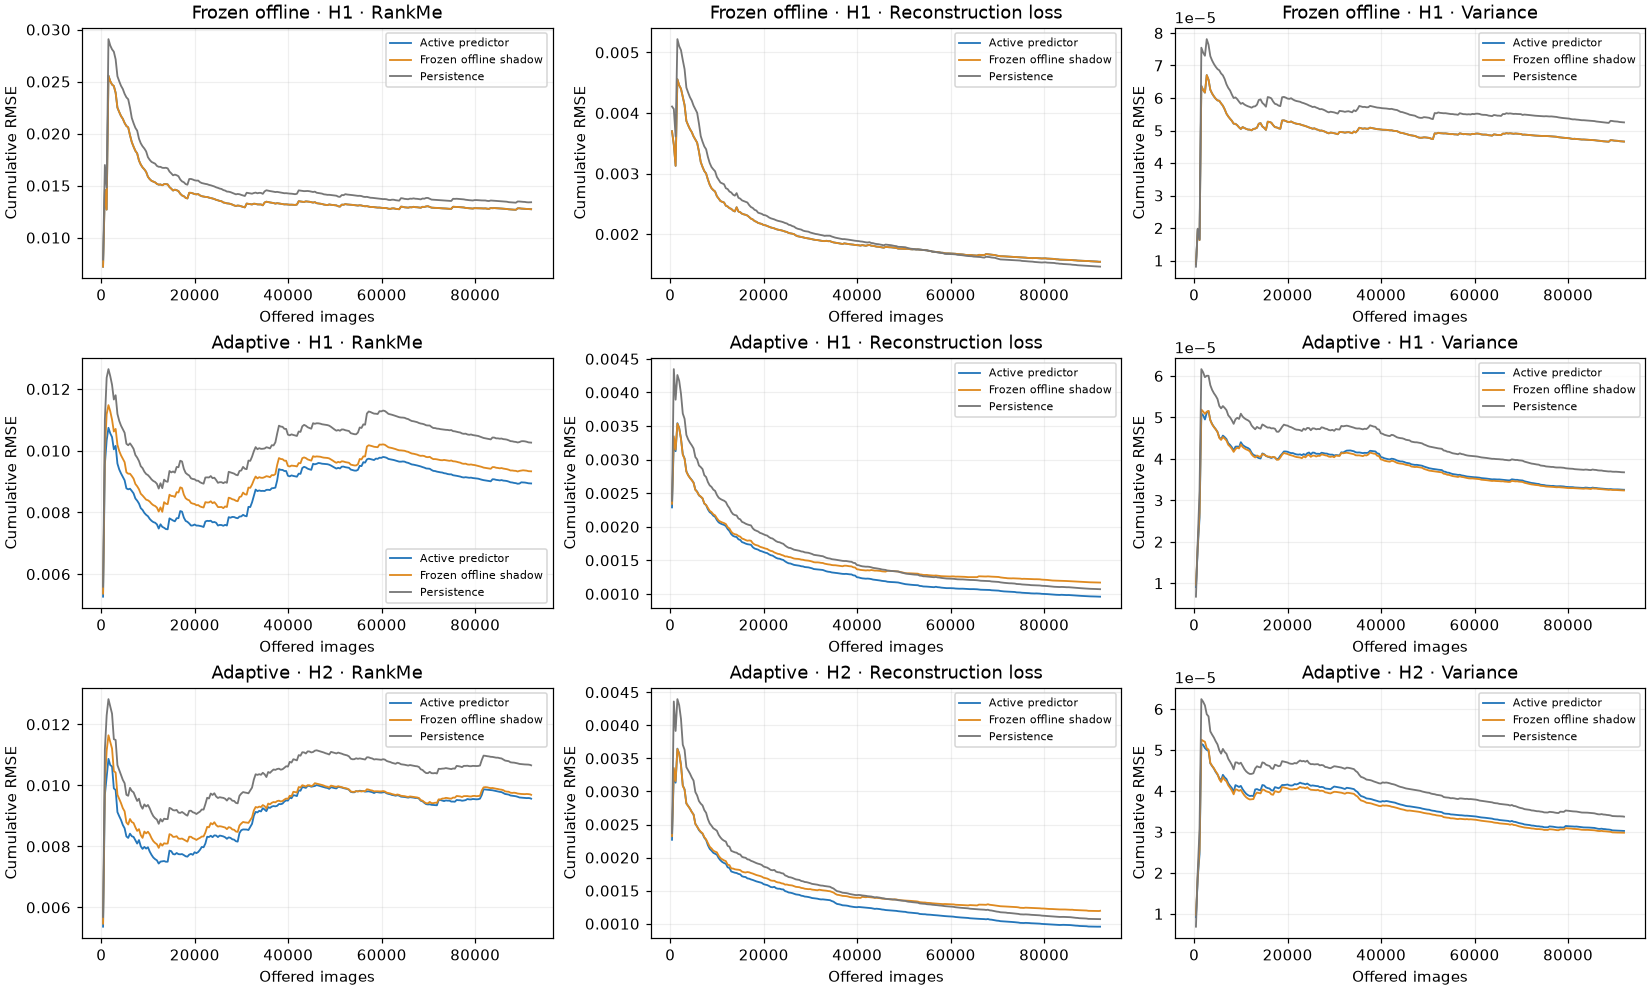



## Plant update and rate budgets

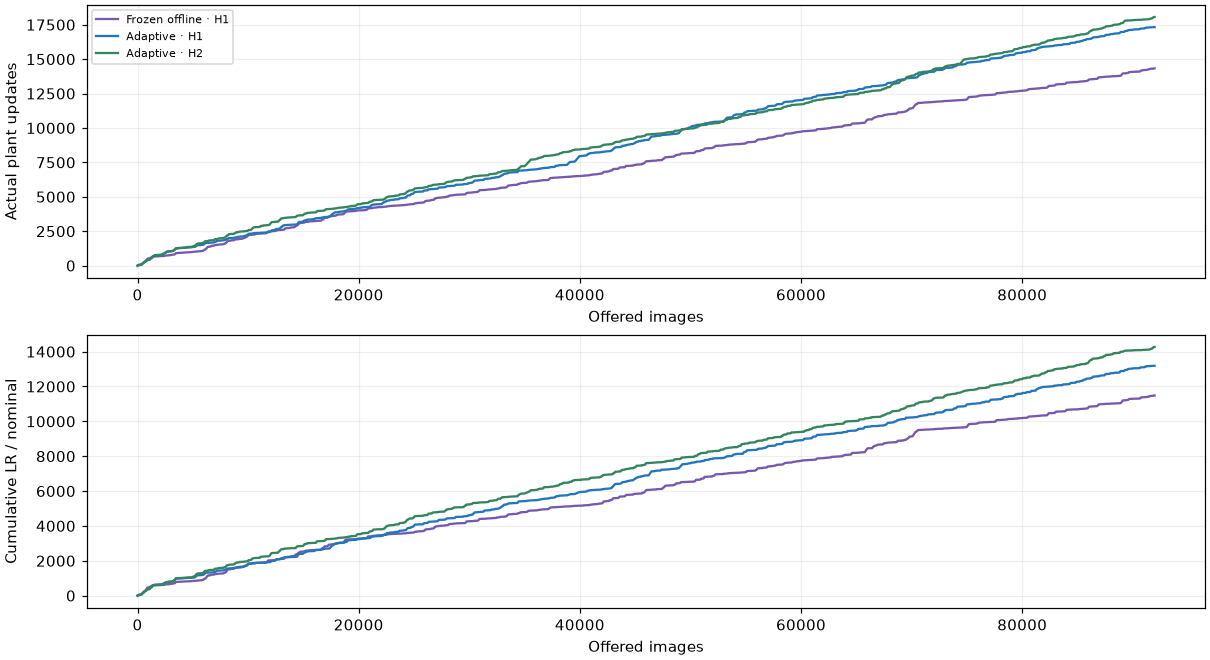



## Transition-model adaptation (frozen arm stays fixed)

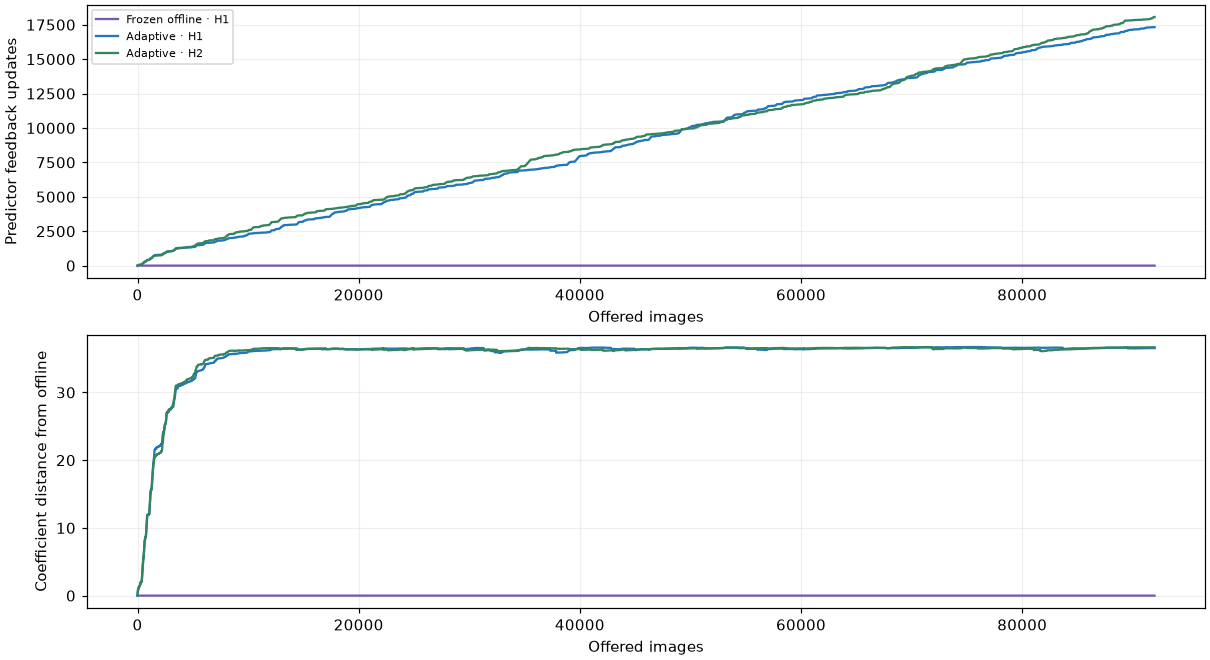



## Executed learning-rate actions

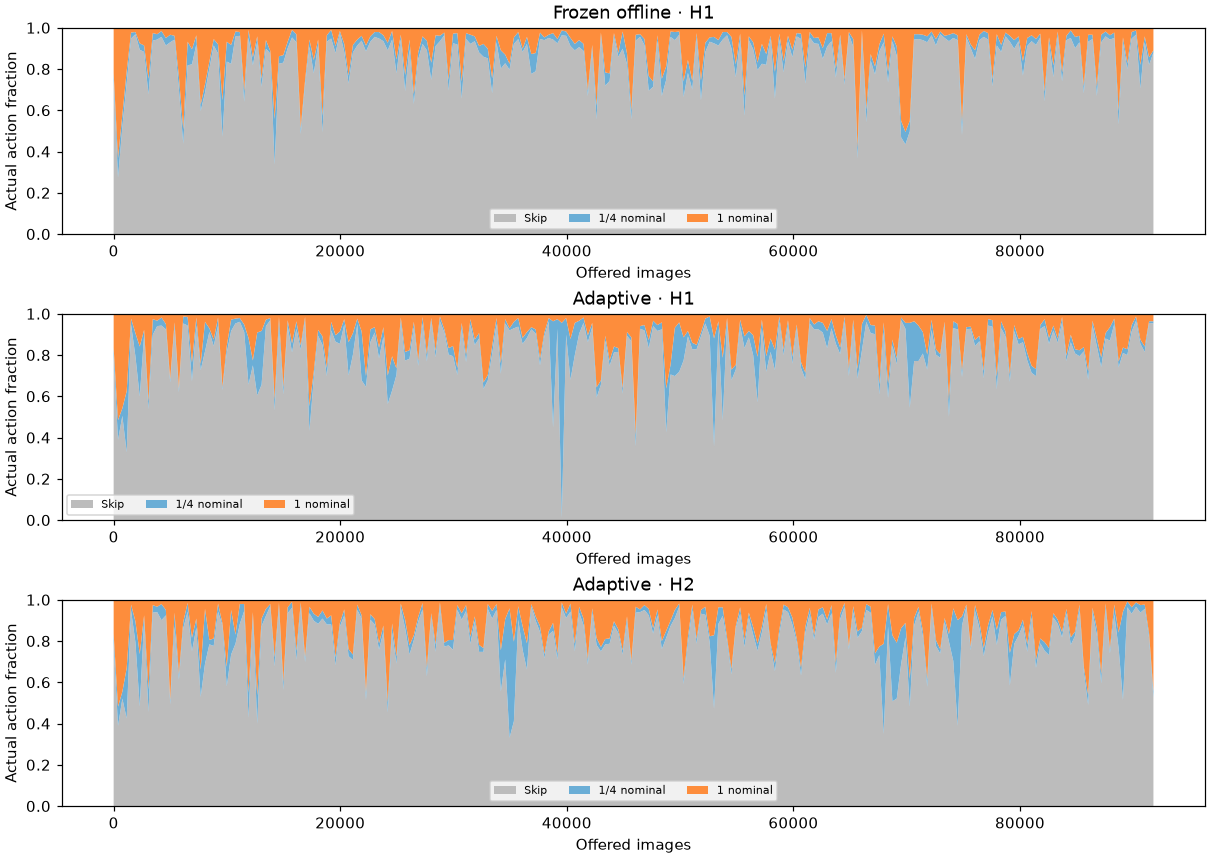



## Actual trained-image losses

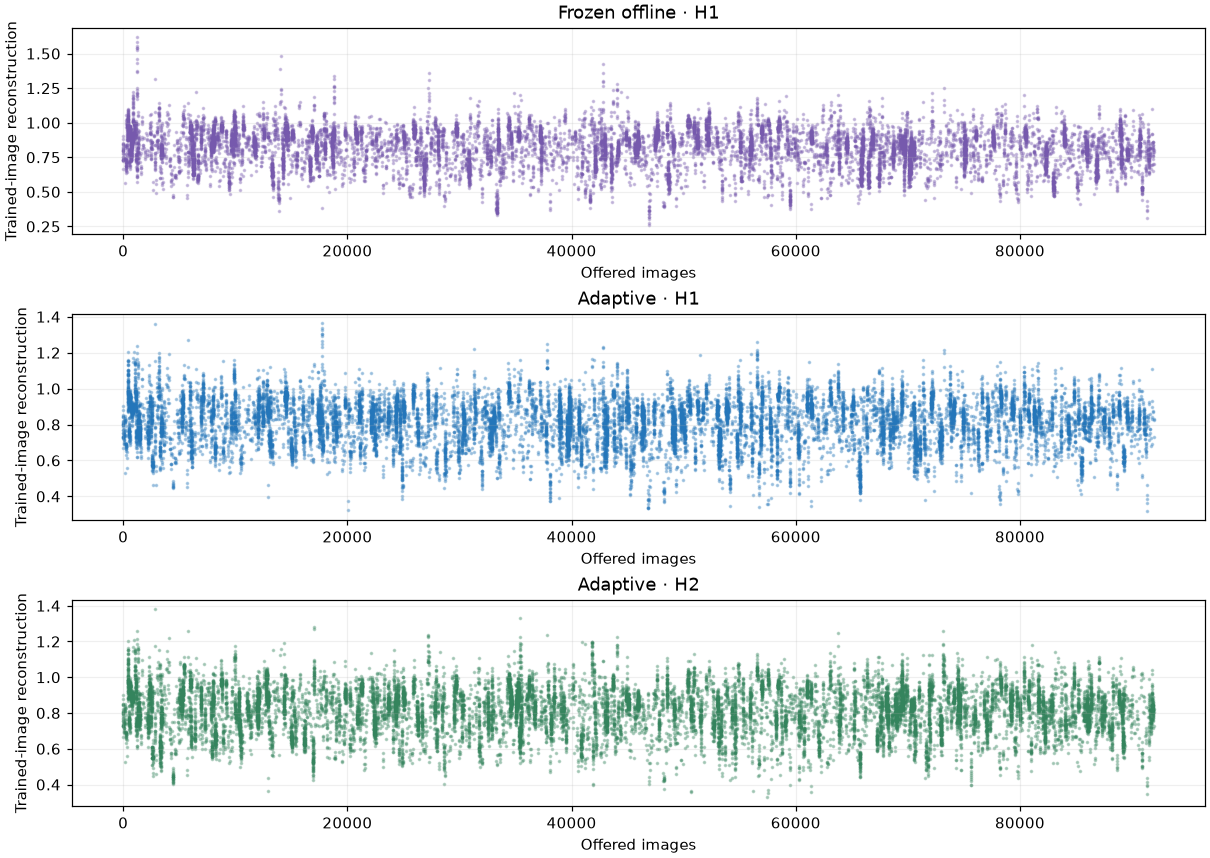



## Audit: linear task metrics

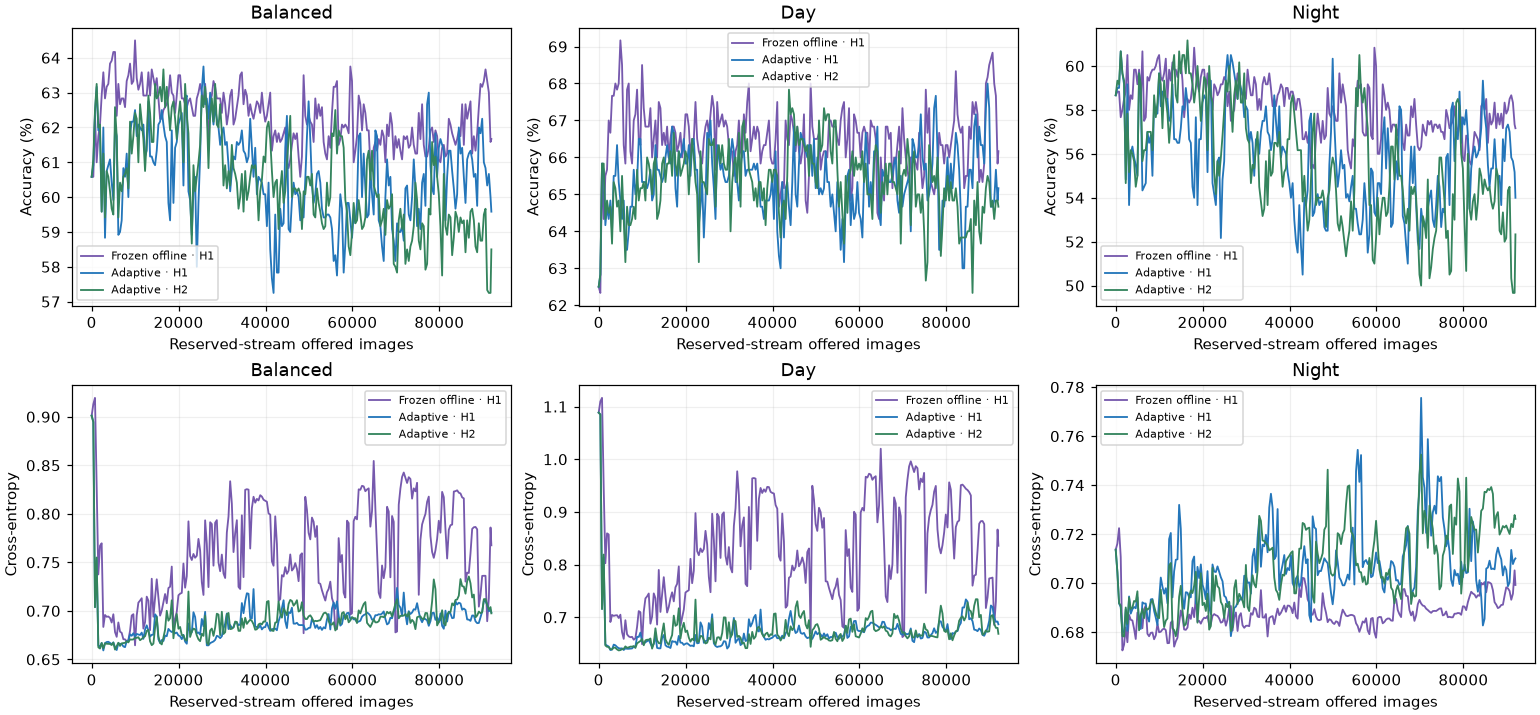



## Audit: knn task metrics

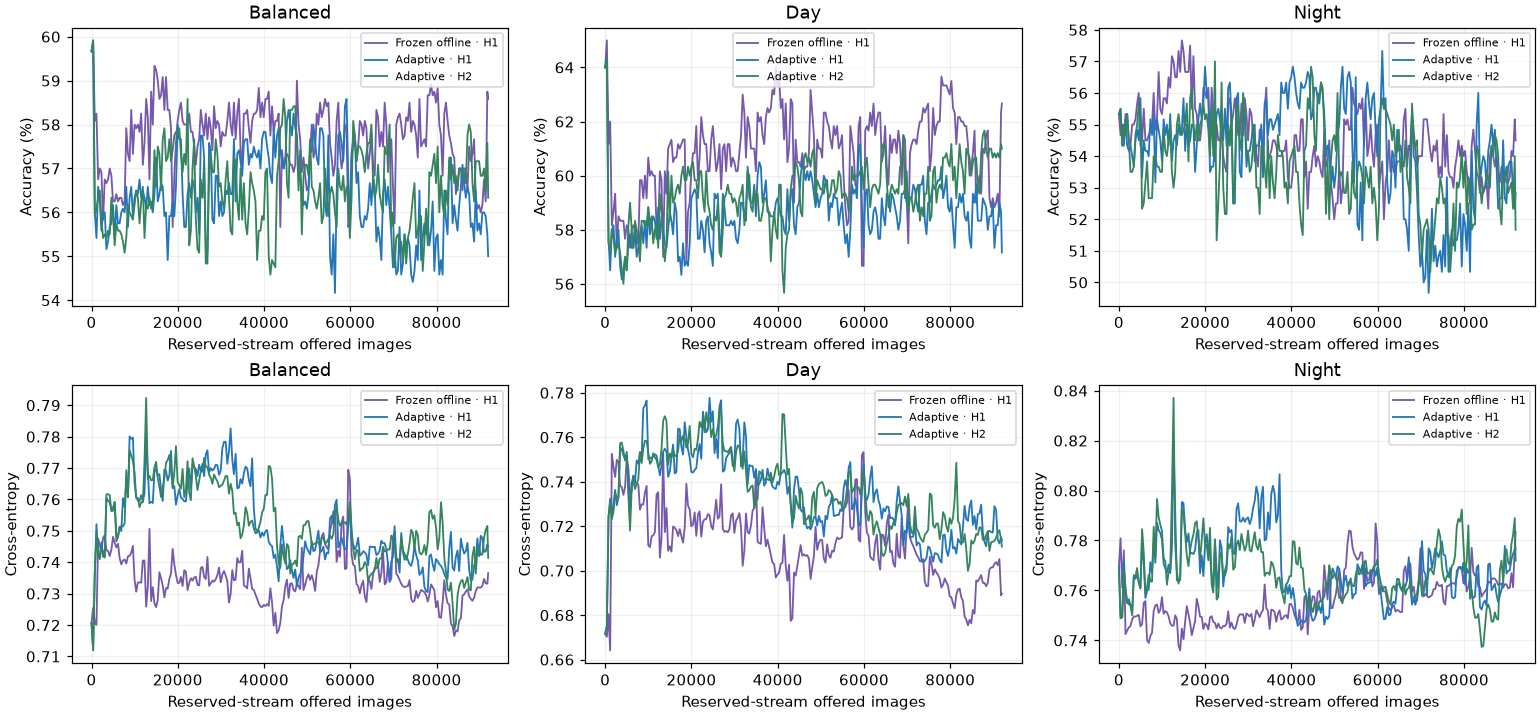



## Previous evaluation: linear task metrics

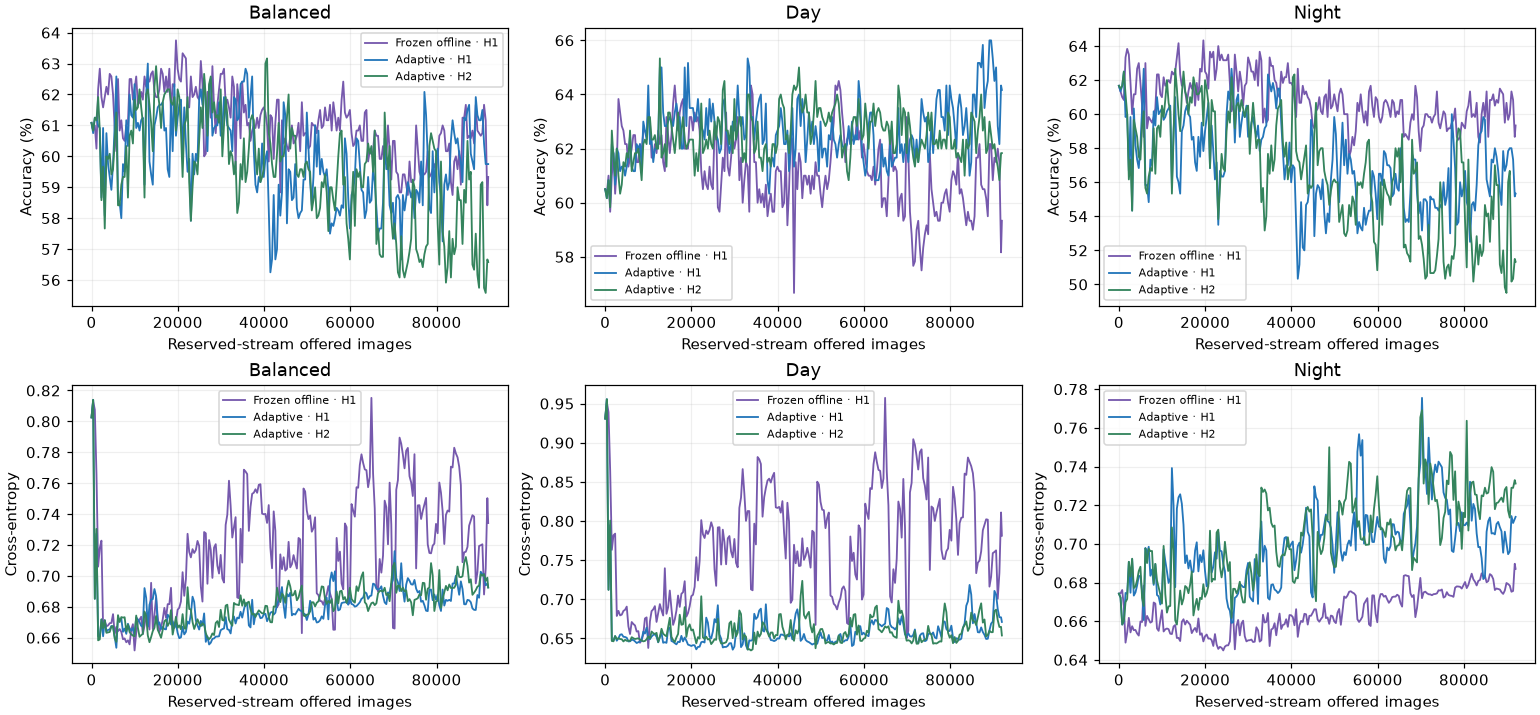



## Previous evaluation: knn task metrics

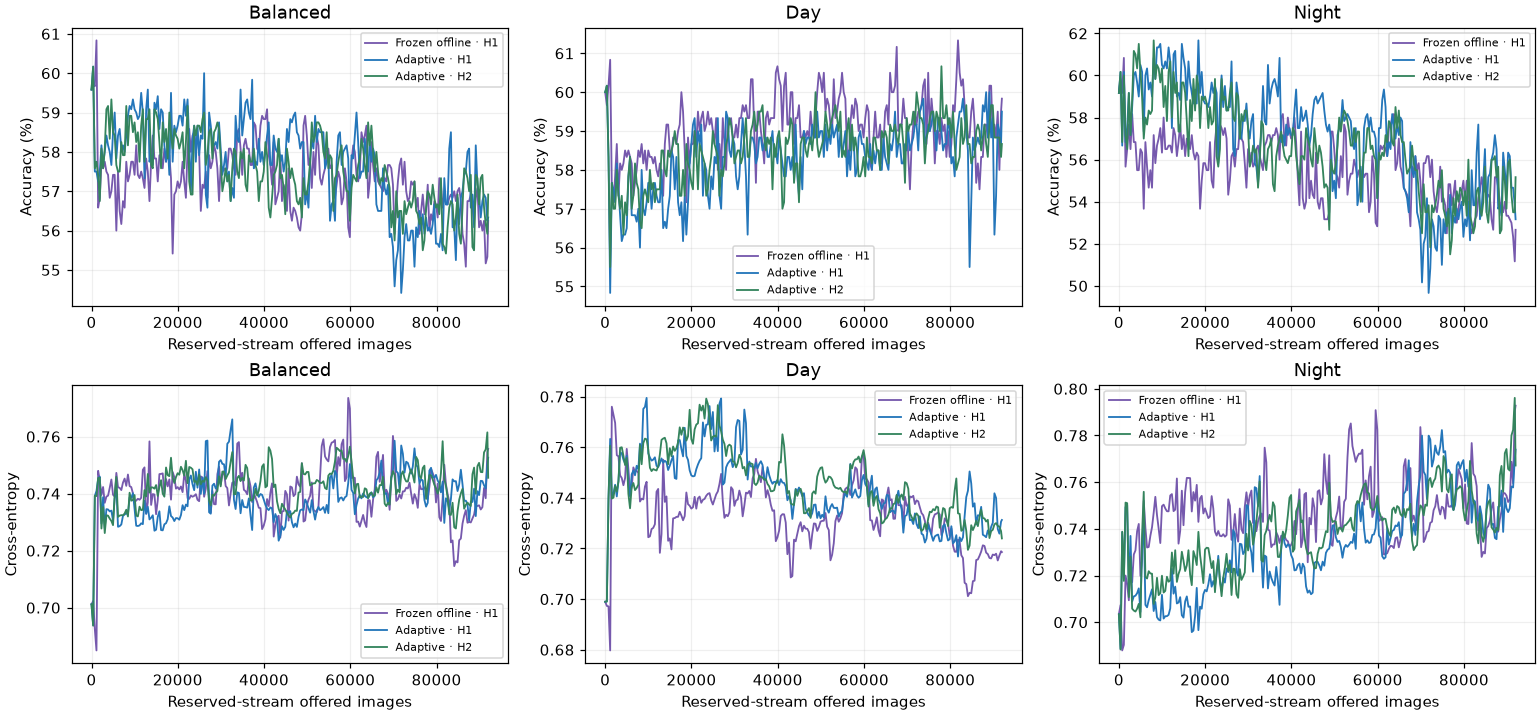



## Additional representation metrics

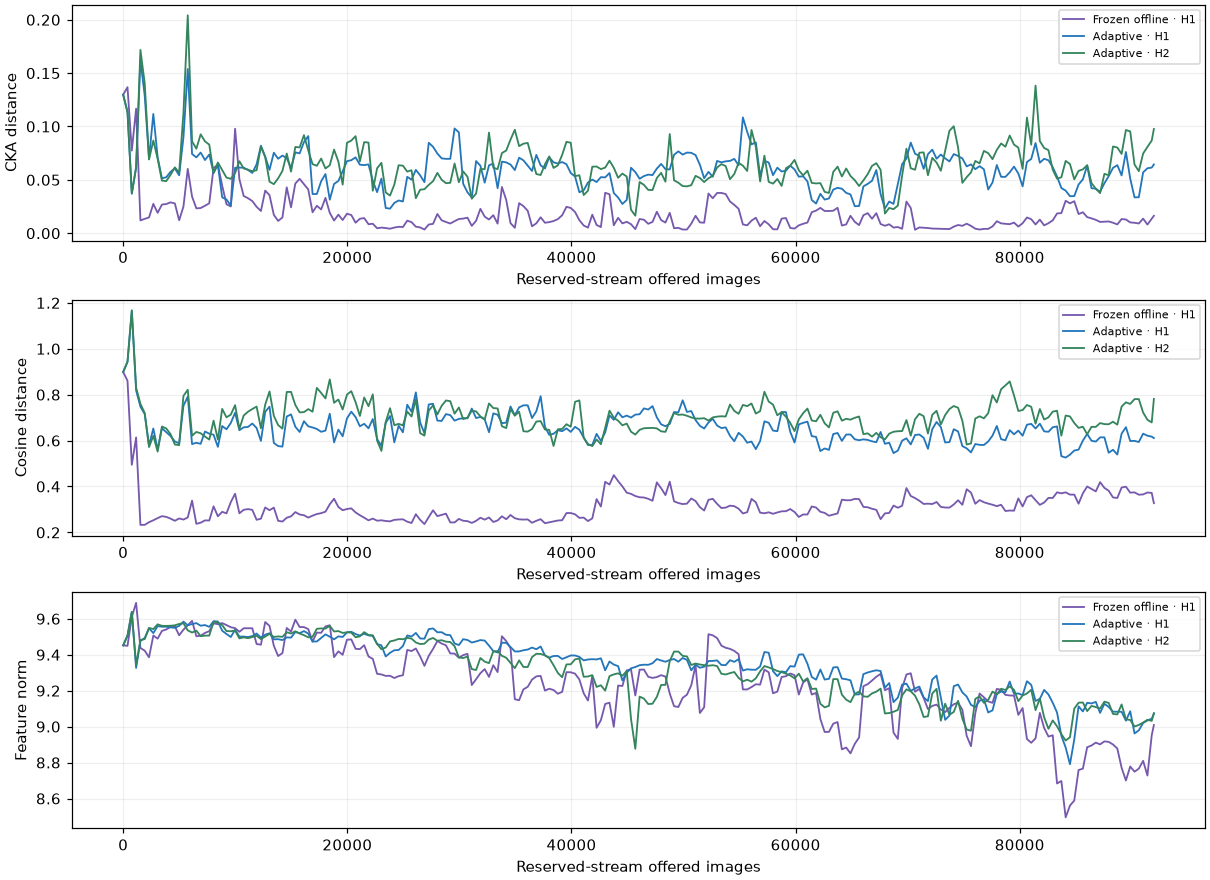



## Secondary evaluation health

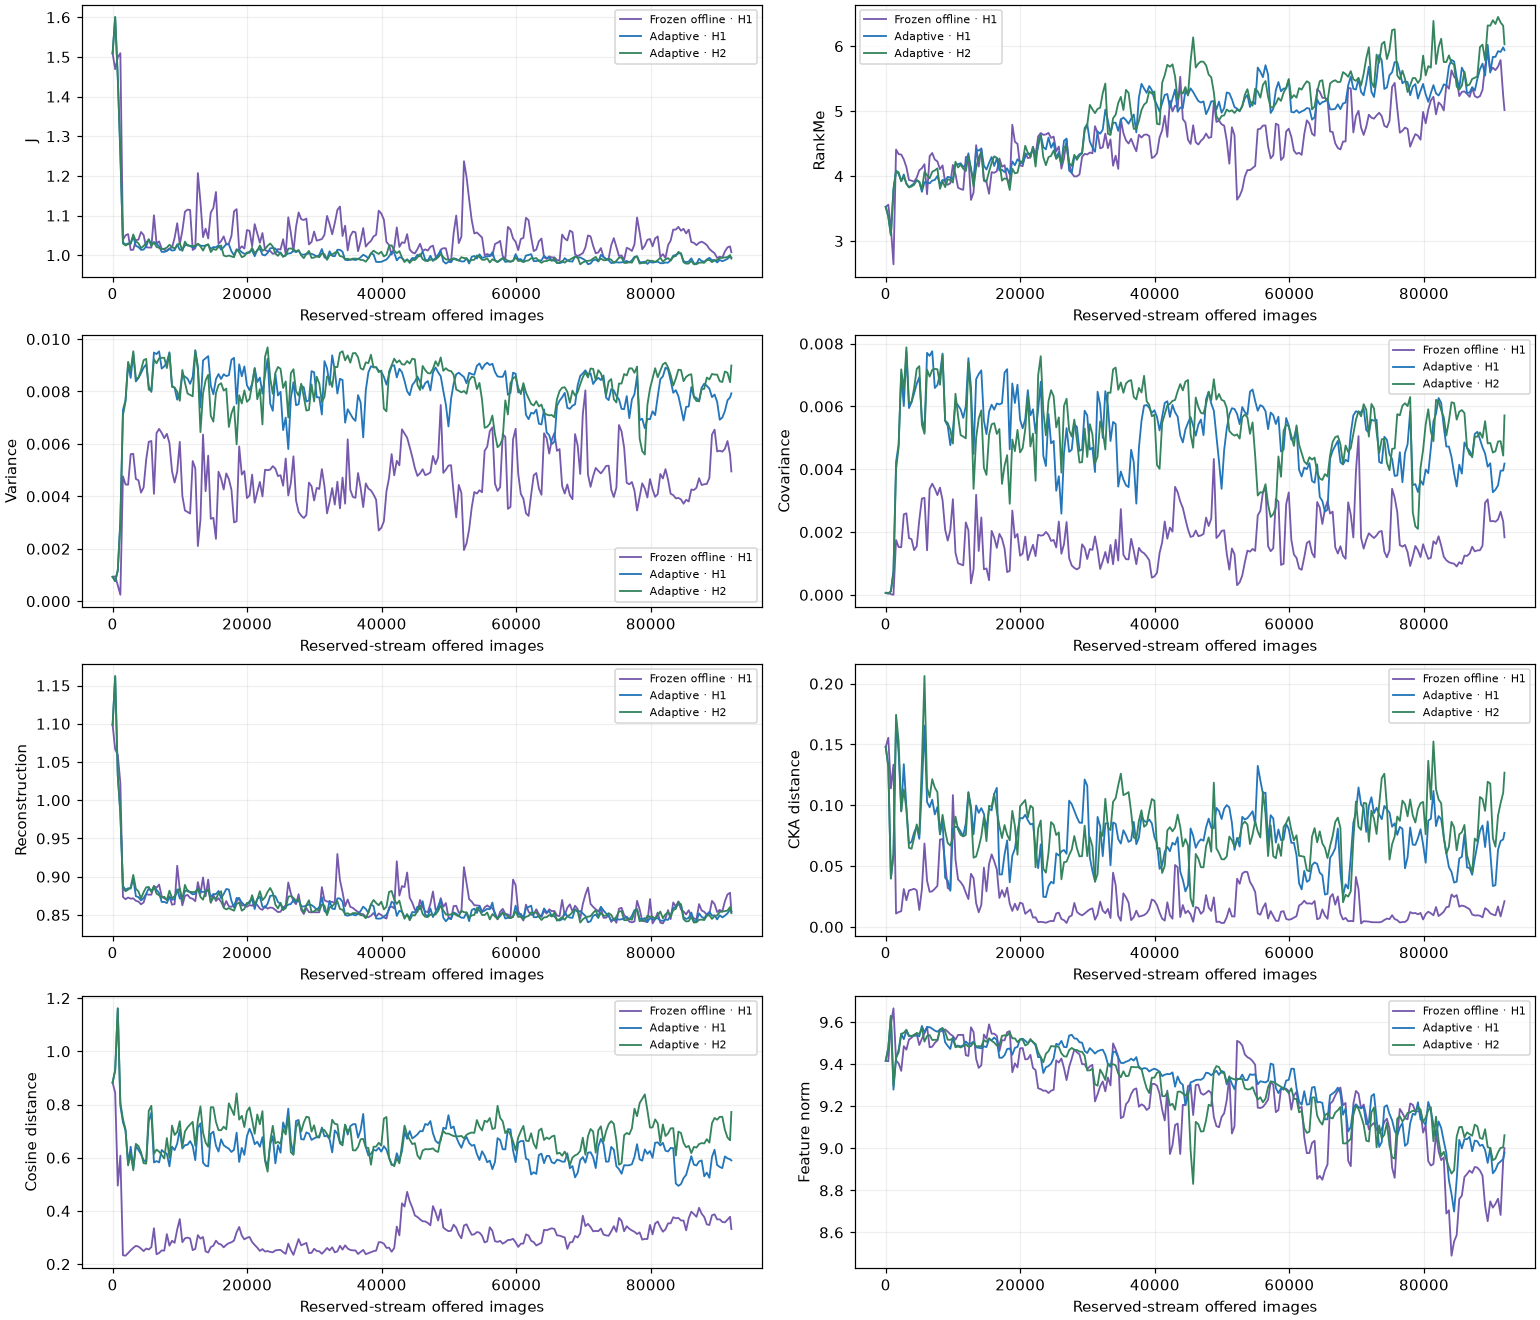

